# Anomaly analysis

Magnetic response of the buried iron objects in the Proefveld survey.
All processing lives in `src/anomaly.py`; this notebook only plots.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src"))

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import LogLocator, ScalarFormatter

import anomaly as an
from dataloader import load_survey, load_object_locations

In [11]:
SURVEY_INDEX = 1
SURVEY_SPEED = 1.25    # m/s
WINDOW_SIZE = 1000     # samples on each side of the anomaly
FS = 200               # Hz

survey = load_survey(SURVEY_INDEX, SURVEY_SPEED)
objects, nearest_points = an.match_nearest_samples(survey, load_object_locations())
windows = an.extract_dipole_windows(survey, nearest_points, window_size=WINDOW_SIZE, fs=FS)
windows_norm = an.normalize_windows(windows, filtered=True)

print(f"Distance between the objects: {an.object_spacing(objects):.2f} m")
objects

[INFO] Matched position file: 2025-01-21-11-16-00-position.csv → overlapping with 2025-01-21_11-15-51_MD-R4_#0077_gga.csv
Distance between the objects: 0.98 m


,Name,Longitude [m],Latitude [m],Nearest_Point_Index,Distance_to_Nearest_Point
0,bol 1 kant bergop,553891.130574,5.645508e+06,304105,0.084611
1,bol 2 kant proefhoeve,553891.766999,5.645507e+06,304236,0.176020


## Anomaly location

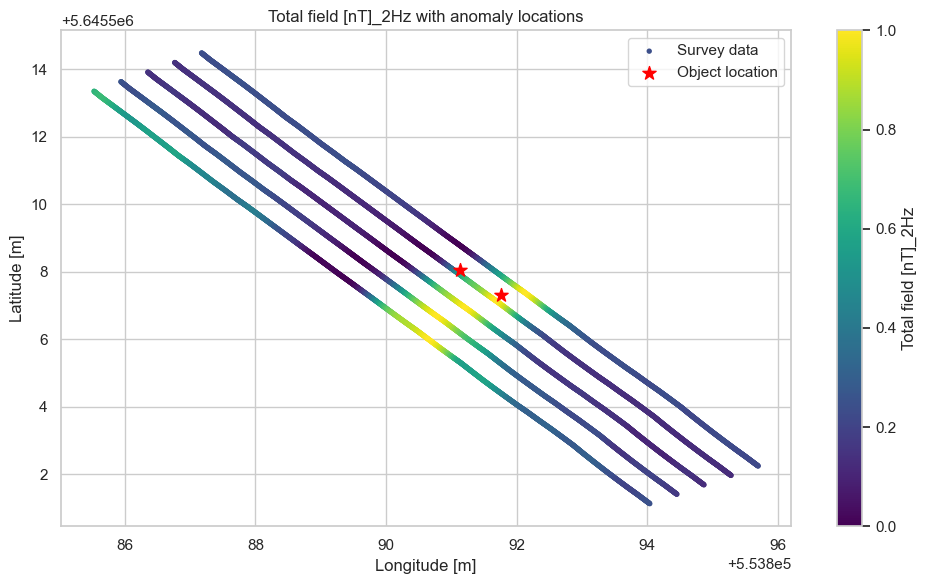

In [12]:
def plot_dipole_area(data, objects, component="Total field [nT]", filtered=False):
    key = component + an.FILTER_SUFFIX if filtered else component

    plt.figure(figsize=(10, 6))
    plt.scatter(data["Longitude [m]"], data["Latitude [m]"], c=data[key], s=8, cmap="viridis", label="Survey data")
    plt.colorbar(label=key)
    plt.scatter(objects["Longitude [m]"], objects["Latitude [m]"],
                color="red", marker="*", s=100, label="Object location")

    plt.xlabel("Longitude [m]")
    plt.ylabel("Latitude [m]")
    plt.title(f"{key} with anomaly locations")
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()

plot_dipole_area(windows_norm, objects, "Total field [nT]", filtered=True)

## Dipole response per sensor

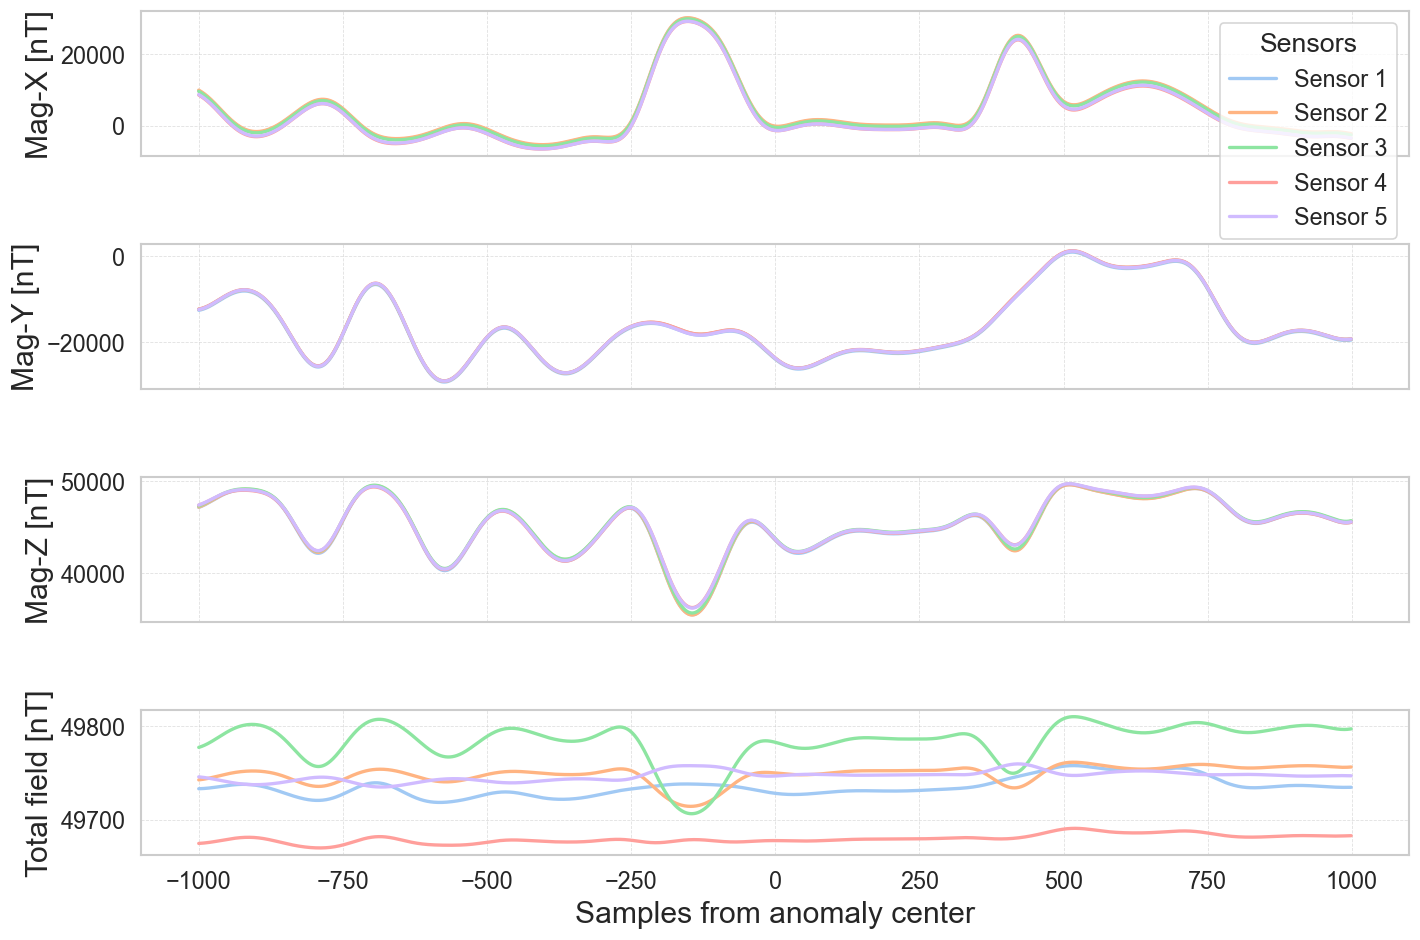

In [4]:
def plot_dipole_response(windows, components=an.COMPONENTS, filtered=True, figsize=(12, 8), dpi=120):
    sns.set_theme(style="whitegrid", font_scale=1.0)

    sensors = windows["Sensor ID"].unique()
    colors = sns.color_palette("pastel", len(sensors))
    fig, axs = plt.subplots(len(components), 1, figsize=figsize, dpi=dpi, sharex=True, squeeze=False)
    axs = axs[:, 0]

    for ax, component in zip(axs, components):
        y_key = component + an.FILTER_SUFFIX if filtered else component
        for sensor_id, color in zip(sensors, colors):
            df = windows[windows["Sensor ID"] == sensor_id]
            center_idx = df["Center_Idx"].iloc[0]
            x = np.arange(-center_idx, len(df) - center_idx)
            ax.plot(x, df[y_key], label=f"Sensor {sensor_id}", color=color, linewidth=2)

        ax.set_ylabel(component, fontsize=18)
        ax.tick_params(labelsize=14)
        ax.grid(True, linestyle="--", linewidth=0.5, alpha=0.6)

    axs[-1].set_xlabel("Samples from anomaly center", fontsize=18)
    axs[0].legend(title="Sensors", fontsize=14, title_fontsize=16, loc="upper right")
    plt.tight_layout()
    plt.show()

plot_dipole_response(windows, filtered=True)

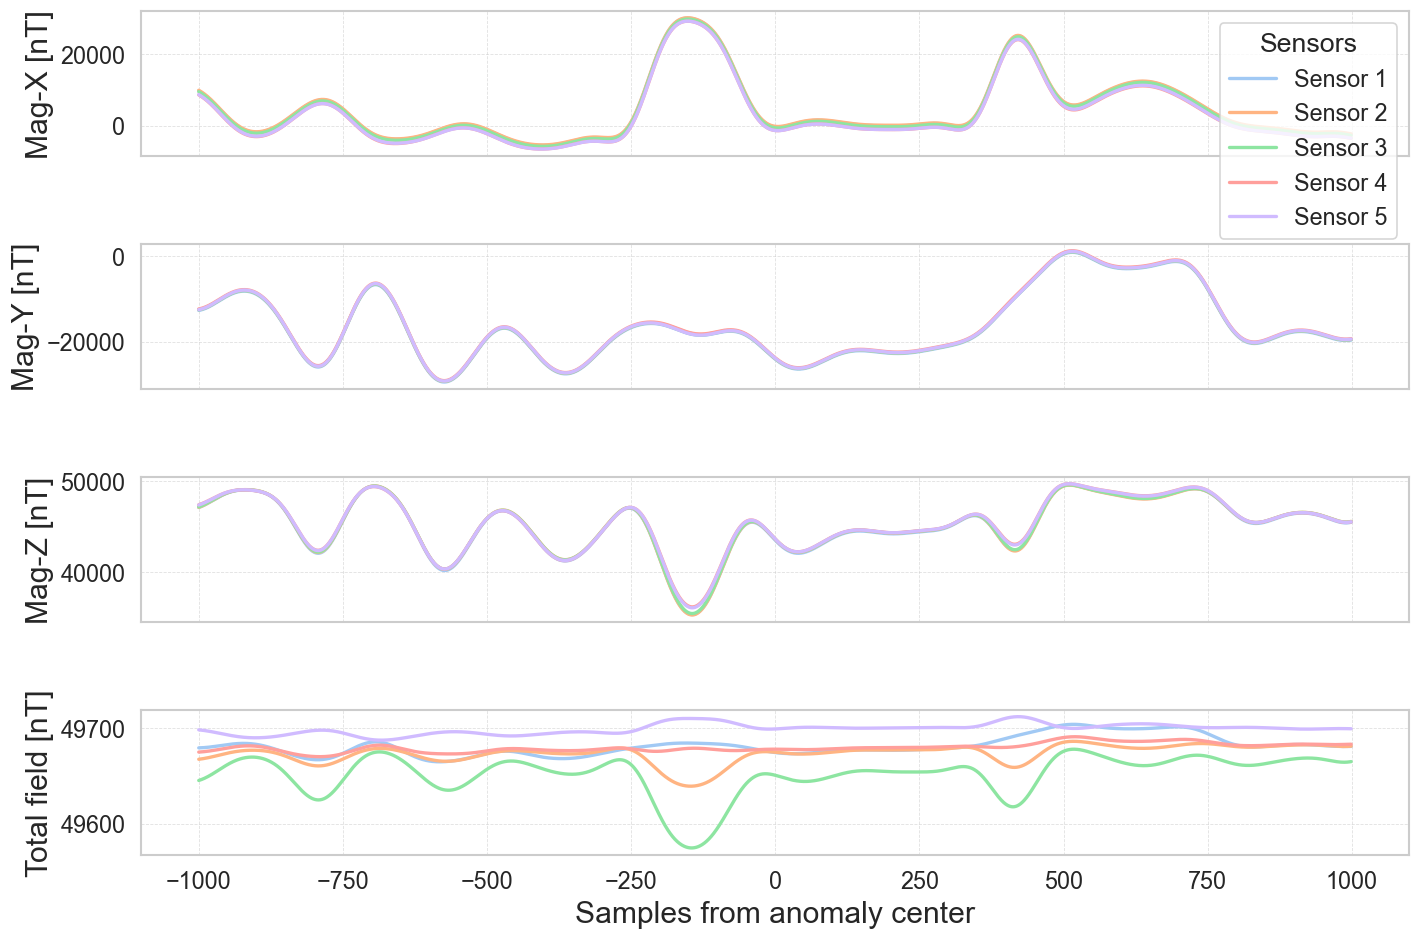

In [5]:
# Bias corrected (constant sensor offsets in an.SENSOR_BIAS removed)
filtered_cols = [c + an.FILTER_SUFFIX for c in an.COMPONENTS]
plot_dipole_response(an.remove_sensor_bias(windows, filtered_cols), filtered=True)

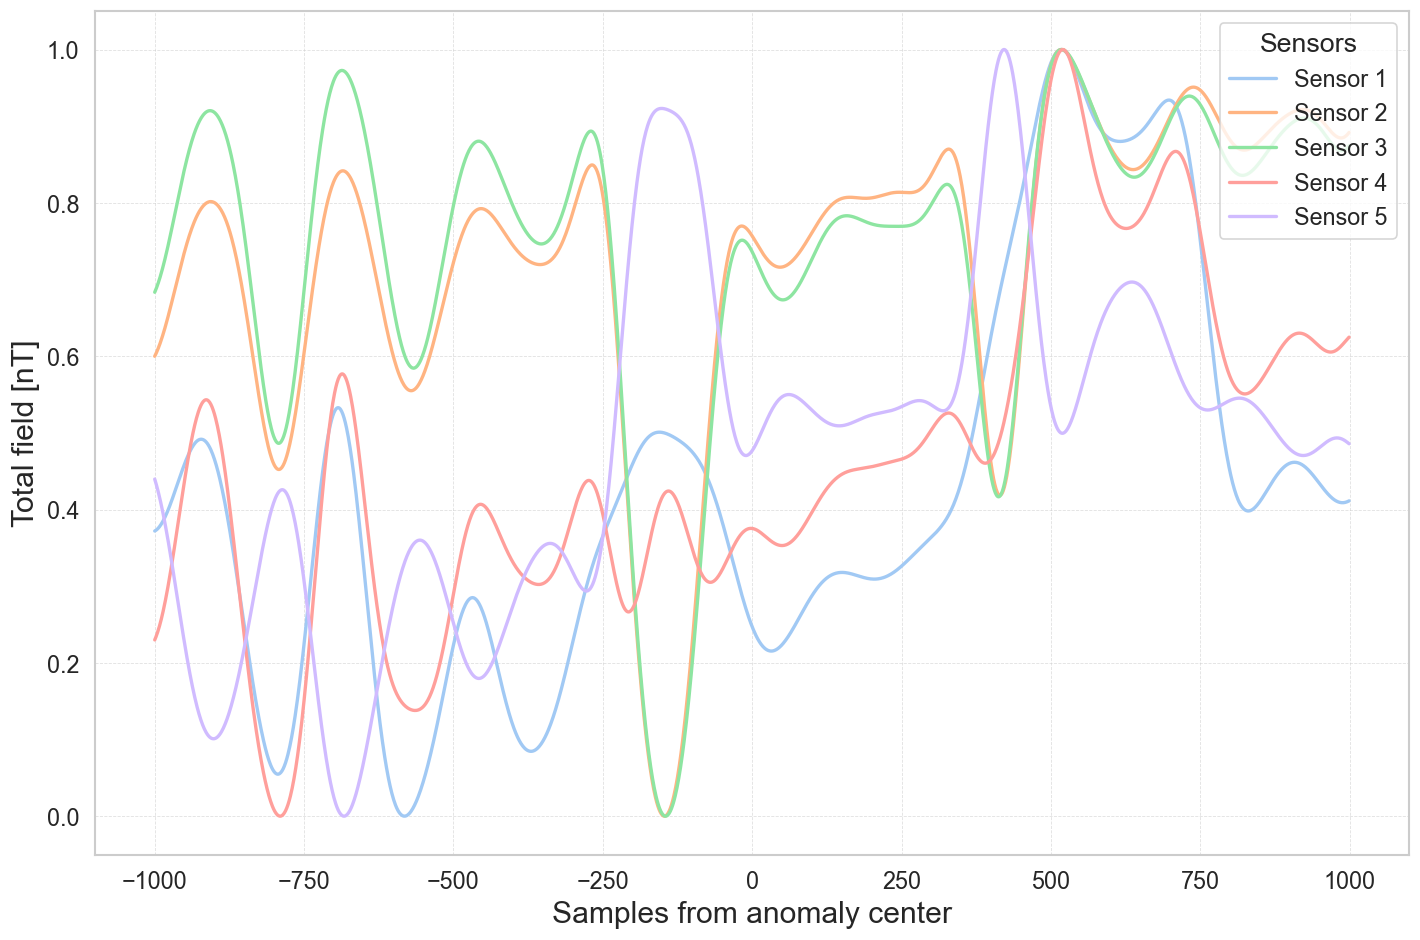

In [6]:
plot_dipole_response(windows_norm, components=["Total field [nT]"], filtered=True)

## Wavelet response (sensor 2)

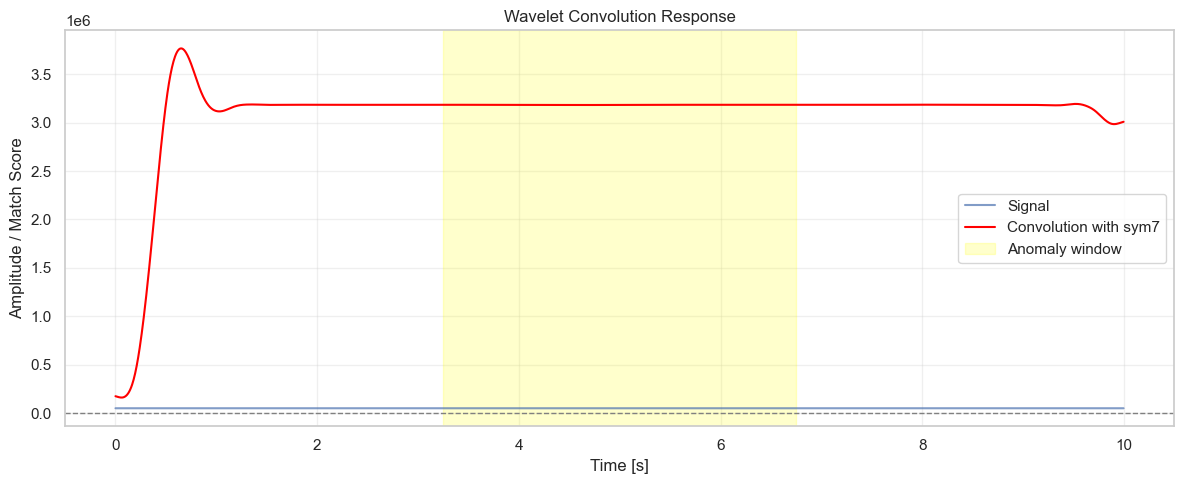

In [7]:
signal_anomaly = an.sensor_signal(windows, sensor_id=2)
conv_result = an.wavelet_convolution(signal_anomaly, wavelet="sym7")

anomaly_start, anomaly_end = 650, 1350
t = np.arange(len(signal_anomaly)) / FS

plt.figure(figsize=(12, 5))
plt.plot(t, signal_anomaly, label="Signal", alpha=0.7)
plt.plot(t, conv_result, label="Convolution with sym7", color="red", linewidth=1.5)
plt.axhline(0, color="gray", linestyle="--", linewidth=1)
plt.axvspan(anomaly_start / FS, anomaly_end / FS, color="yellow", alpha=0.2, label="Anomaly window")
plt.xlabel("Time [s]")
plt.ylabel("Amplitude / Match Score")
plt.title("Wavelet Convolution Response")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

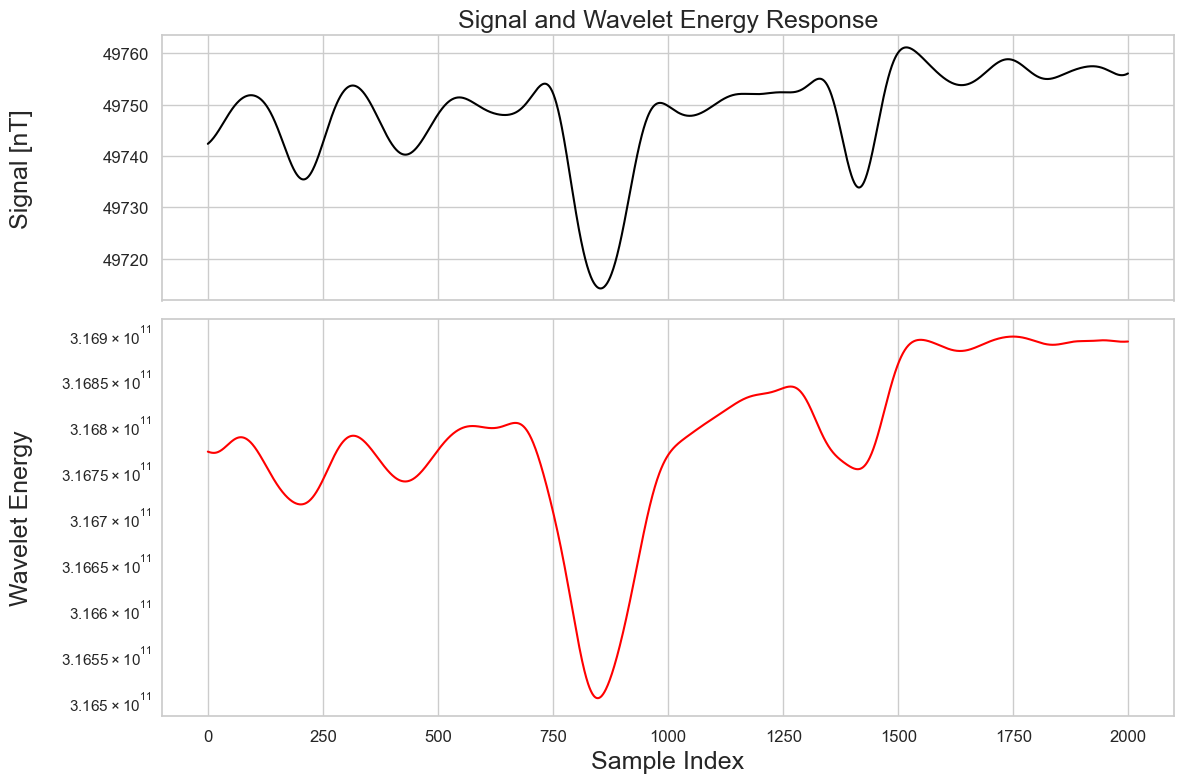

In [8]:
response = an.sliding_wavelet_energy(signal_anomaly, an.wavelet_kernel("sym7", level=7))

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 8), sharex=True, gridspec_kw={"height_ratios": [1, 1.5]})

ax1.plot(signal_anomaly, color="black")
ax1.set_ylabel("Signal [nT]", fontsize=18, labelpad=20)
ax1.set_title("Signal and Wavelet Energy Response", fontsize=18)

ax2.plot(response, color="red")
ax2.set_yscale("log")
ax2.set_ylabel("Wavelet Energy", fontsize=18, labelpad=20)
ax2.set_xlabel("Sample Index", fontsize=18)
ax2.yaxis.set_major_locator(LogLocator(base=10.0, subs=[1.0], numticks=6))
ax2.yaxis.set_minor_locator(LogLocator(base=10.0, subs=np.arange(2, 10) * 0.1, numticks=10))
ax2.yaxis.set_major_formatter(ScalarFormatter())
ax2.ticklabel_format(axis="y", style="sci", scilimits=(0, 0))

for ax in (ax1, ax2):
    ax.tick_params(axis="both", which="major", labelsize=12)
fig.align_ylabels([ax1, ax2])

plt.tight_layout()
plt.show()

## SNR of the total field

In [9]:
an.snr_table(windows, filtered=False, window_size=WINDOW_SIZE)

,Sensor ID,SNR,Peak-to-peak [nT],Noise StdDev [nT]
0,1,1.90,22.17,11.69
1,2,6.83,56.19,8.23
2,3,7.26,117.24,16.16
3,4,3.30,34.50,10.45
4,5,3.51,20.93,5.96


In [10]:
an.snr_table(windows, filtered=True, window_size=WINDOW_SIZE)

,Sensor ID,SNR,Peak-to-peak [nT],Noise StdDev [nT]
0,1,1.36,15.78,11.61
1,2,5.92,40.85,6.90
2,3,6.41,92.29,14.39
3,4,1.03,5.41,5.24
4,5,2.76,15.48,5.61
